**K-Means Clustering**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [55]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
path='/content/drive/My Drive/ML Lab/Exp08/customer.csv'
df=pd.read_csv(path)
print(df)

          ID  Gender Ever_Married  Age Graduated     Profession  \
0     462809    Male           No   22        No     Healthcare   
1     462643  Female          Yes   38       Yes       Engineer   
2     466315  Female          Yes   67       Yes       Engineer   
3     461735    Male          Yes   67       Yes         Lawyer   
4     462669  Female          Yes   40       Yes  Entertainment   
...      ...     ...          ...  ...       ...            ...   
8063  464018    Male           No   22        No            NaN   
8064  464685    Male           No   35        No      Executive   
8065  465406  Female           No   33       Yes     Healthcare   
8066  467299  Female           No   27       Yes     Healthcare   
8067  461879    Male          Yes   37       Yes      Executive   

      Work_Experience Spending_Score  Family_Size  Var_1 Segmentation  
0                 1.0            Low          4.0  Cat_4            D  
1                 NaN        Average          3.0  

In [56]:
# Remove ID column
data = df.drop(columns=["ID"]).copy()
data = df.drop(columns=["Var_1"]).copy()
# Handle missing values
for col in data.columns:
    if data[col].dtype == "object":
        data[col] = data[col].fillna(data[col].mode()[0])
    else:
        data[col] = data[col].fillna(data[col].median())

# Convert categorical columns into numerical columns
data = pd.get_dummies(data, drop_first=True, dtype=int)
data=df.head(50)
print(data.head())
print(data.shape)

       ID  Gender Ever_Married  Age Graduated     Profession  Work_Experience  \
0  462809    Male           No   22        No     Healthcare              1.0   
1  462643  Female          Yes   38       Yes       Engineer              NaN   
2  466315  Female          Yes   67       Yes       Engineer              1.0   
3  461735    Male          Yes   67       Yes         Lawyer              0.0   
4  462669  Female          Yes   40       Yes  Entertainment              NaN   

  Spending_Score  Family_Size  Var_1 Segmentation  
0            Low          4.0  Cat_4            D  
1        Average          3.0  Cat_4            A  
2            Low          1.0  Cat_6            B  
3           High          2.0  Cat_6            B  
4           High          6.0  Cat_6            A  
(50, 11)


In [58]:
#Feature
scaler = StandardScaler()
X_scaled = scaler.fit_transform(data)

print(X_scaled[:5])

ValueError: could not convert string to float: 'Male'

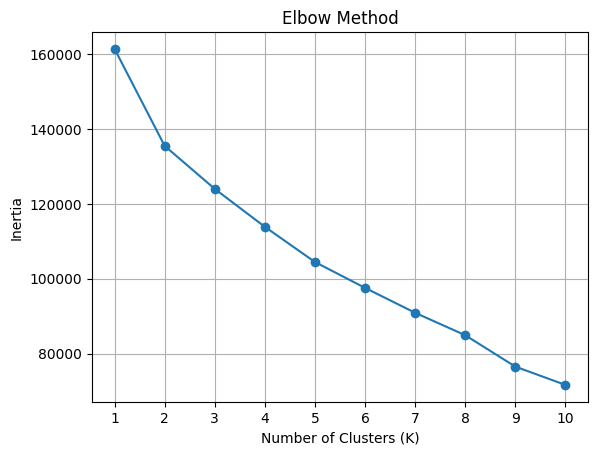

In [41]:
inertia = []
for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)
plt.plot(range(1, 11), inertia, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [51]:
k = 5
kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)
labels = kmeans.fit_predict(X_scaled)
# Add cluster labels to the original dataset
df["Cluster"] = labels
print(df[["Age", "Gender", "Spending_Score", "Cluster"]].head())

   Age  Gender Spending_Score  Cluster
0   22    Male            Low        4
1   38  Female        Average        1
2   67  Female            Low        1
3   67    Male           High        3
4   40  Female           High        1


In [52]:
print("Cluster Centroids:")
print(kmeans.cluster_centers_)

print("\nNumber of customers in each cluster:")
print(df["Cluster"].value_counts().sort_index())

Cluster Centroids:
[[ 0.47360226 -0.101477    0.38032966 -0.47006542  0.81768835  0.72233519
  -0.22954021 -0.30532758 -0.30798836 -0.3651099   3.53116343 -0.44468356
  -0.17734079 -0.28927551 -0.19378194  1.45467174 -0.82270783  0.18599548
   0.11856491 -0.20893907]
 [ 0.30190121 -0.07719407 -0.02465586 -1.0605197   0.01952019  0.81029273
   0.30772292 -0.03567129  0.1074864   0.17324205 -0.28319278 -0.39838948
   0.00805062 -0.28927551 -0.11346862 -0.00899697 -0.66838924  0.21084504
   0.35326851 -0.50019996]
 [-0.46531404  0.25210324 -0.22495112  1.30129741 -0.2440998  -0.91133207
  -0.04328393  0.3716956   0.17922654  0.15091227 -0.27351168 -0.44354419
   0.17694558 -0.28610615  0.35885345 -0.41772063  0.78704651 -0.12901901
  -0.3153201   0.18203799]
 [ 1.91003561 -0.39293892 -0.57968521  0.71179395 -0.07758007  0.70418953
   0.01532286 -0.30532758 -0.30798836 -0.3651099  -0.28319278 -0.44468356
  -0.17734079  3.45691203 -0.19378194  1.03702214 -0.3177022   0.05350226
  -0.0436029